# 📡 정보통신개론 개별 과제 제출 양식
## 내 목소리로 실습하는 AM · FM 변조와 PCM 부호화

| 항목 | 내용 |
|---|---|
| 제출물 | 이 노트북(실행 결과가 모두 남아 있는 상태) — `.ipynb` 파일 또는 Colab 공유 링크 |
| 파일 이름 | `정보통신개론_번호_이름.ipynb` |
| 진행 방법 | **설계(값 선택·기술) → 코드 작성 → 실행 결과 확인 → 결과 기록** 순서로 각 단계를 작성 |

### 작성 방법
1. **파일 → 드라이브에 사본 저장** 후 작업합니다.
2. 📝 표시 칸(마크다운 셀)은 **더블클릭**하여 `(작성)` 부분을 채웁니다.
3. 💻 표시 칸(코드 셀)에는 **직접 코드를 작성**하고 실행합니다. 셀 맨 위 주석의 **"반드시 나와야 할 것"** 이 출력되어야 합니다.
4. **변조·부호화 코드를 작성하기 전에 반드시 설계표(사용할 주파수, 변조지수 등)를 먼저 작성**합니다.
5. 모든 그래프 제목에는 **본인 번호와 이름**이 들어가도록 합니다.
6. 제출 전 **런타임 → 모두 실행**으로 오류 없이 결과가 나오는지 확인합니다.

## 1. 제출자 정보 📝

| 항목 | 내용 |
|---|---|
| 번호 | 03 |
| 이름 | 권신협 |
| 제출일 | 2026년 10월 22일 |

---
## 2. 본인 음성 신호 입력

In [11]:
# ===== 2-2. 라이브러리 불러오기 · 기본 설정 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 사용할 라이브러리 import
#   2) 그래프 한글 글꼴 설정 (한글이 깨지지 않을 것)
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
import os, sys, glob, subprocess, hashlib, base64
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import signal
from scipy.io import wavfile
from scipy.special import erfc
import subprocess, base64
from IPython.display import Audio, Javascript, display
from google.colab import output, files

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# 한글 폰트 설치 및 등록
if IN_COLAB and not glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"):
    subprocess.run("apt-get -qq -y install fonts-nanum > /dev/null", shell=True)
font_files = (glob.glob("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
              + glob.glob("/usr/share/fonts/**/NotoSansCJK*-Regular.ttc", recursive=True))
if font_files:
    fm.fontManager.addfont(font_files[0])
    plt.rc("font", family=fm.FontProperties(fname=font_files[0]).get_name())

# 그래프 기본 스타일 (흑백 위주)
plt.rcParams.update({
    "axes.unicode_minus": False, "figure.figsize": (10, 3.2), "figure.dpi": 100,
    "axes.grid": True, "grid.color": "#dddddd", "axes.prop_cycle": plt.cycler(color=["black", "gray", "darkgray"]),
})

def play(x, fs, label=""):
    """소리 재생 플레이어 표시"""
    print(f"[소리 재생] {label}")
    try:
        from IPython.display import Audio, display
        display(Audio(np.asarray(x, dtype=float), rate=int(fs)))
    except ImportError:
        pass

def spectrum(x, fs):
    """주파수 스펙트럼 (최대값 기준 dB)"""
    X = np.abs(np.fft.rfft(x * np.hanning(len(x)))) + 1e-12
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, 20 * np.log10(X / X.max())

print("환경 설정 완료 / Colab 환경:", IN_COLAB)

환경 설정 완료 / Colab 환경: True


In [12]:
# ===== 2-3. 음성 신호 입력 모듈 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 본인 음성을 녹음(또는 업로드)하여 배열로 불러오기
#   2) 샘플링 주파수, 표본 수, 녹음 길이(초) 출력
#   3) 녹음한 음성을 재생할 수 있는 플레이어 (IPython.display.Audio)
#
# [참고]
#   - 녹음: google.colab.output + JavaScript MediaRecorder / 업로드: google.colab.files.upload()
#   - 변환·읽기: ffmpeg, scipy.io.wavfile, librosa 등 자유
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
SOURCE = "upload"      # "upload" | "record" | "sample"
RECORD_SEC = 4         # 녹음 시간(초)
FS_ANALOG = 44100      # '아날로그'로 간주할 고해상도 샘플링 주파수(Hz)
MAX_SEC = 4            # 실습에 사용할 최대 길이(초)

def to_wav(src, dst="voice.wav"):
    """어떤 음성 파일이든 모노 44.1 kHz wav 로 변환해 읽기"""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src,
                    "-ac", "1", "-ar", str(FS_ANALOG), dst], check=True)
    _, data = wavfile.read(dst)
    return data

RECORD_JS = """
const sleep = t => new Promise(r => setTimeout(r, t));
const toB64 = blob => new Promise(res => { const rd = new FileReader();
  rd.onloadend = () => res(rd.result); rd.readAsDataURL(blob); });
var record = async (sec) => {
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); await sleep(sec * 1000); rec.stop();
  await new Promise(r => rec.onstop = r);
  stream.getTracks().forEach(t => t.stop());
  return await toB64(new Blob(chunks));
}
"""

def record(sec):
    """Colab 브라우저 마이크로 녹음"""
    from IPython.display import Javascript, display
    from google.colab.output import eval_js
    display(Javascript(RECORD_JS))
    print(f"{sec}초 동안 녹음합니다. 지금 말씀하세요...")
    data = eval_js(f"record({sec})")
    with open("rec.webm", "wb") as f:
        f.write(base64.b64decode(data.split(",")[1]))
    print("녹음 완료")
    return to_wav("rec.webm")

def sample_voice(sec=3.0, fs=FS_ANALOG):
    """합성 모음 음성 '아-에-이-오-우' (성대 펄스 + 포먼트 공명)"""
    t = np.arange(int(sec * fs)) / fs
    f0 = 140 + 20 * np.sin(2 * np.pi * 0.6 * t) + 4 * np.sin(2 * np.pi * 5.5 * t)   # 음높이 + 떨림
    pulses = np.diff(np.floor(np.cumsum(f0) / fs), prepend=0)                      # 성대 진동 펄스
    src = signal.lfilter([1], [1, -0.95], pulses)
    vowels = [(800, 1200, 2500), (500, 1900, 2500), (300, 2300, 3000), (500, 900, 2400), (330, 800, 2300)]
    seg = len(t) // len(vowels)
    out = []
    for k, formants in enumerate(vowels):
        y = src[k * seg:(k + 1) * seg]
        for F in formants:                                   # 포먼트(공명 주파수) 필터
            r = np.exp(-np.pi * 90 / fs)
            y = signal.lfilter([1 - r], [1, -2 * r * np.cos(2 * np.pi * F / fs), r * r], y)
        env = np.sin(np.linspace(0, np.pi, len(y))) ** 0.6   # 음절 크기 변화
        out.append(y * env)
    return np.concatenate(out)

# ── 음성 불러오기 ──
if SOURCE == "upload" and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    x = to_wav(next(iter(uploaded)))
elif SOURCE == "record" and IN_COLAB:
    x = record(RECORD_SEC)
else:
    if SOURCE != "sample":
        print("Colab 환경이 아니어서 합성 예제 음성을 사용합니다.")
    x = sample_voice()

# ── 정리: 모노, 정규화, 앞 무음 제거, 길이 제한 ──
x = np.asarray(x, dtype=float)
if x.ndim > 1:
    x = x.mean(axis=1)
x = x / (np.abs(x).max() + 1e-12)
start = int(np.argmax(np.abs(x) > 0.05))
x = x[start:start + MAX_SEC * FS_ANALOG]
x = 0.95 * x / np.abs(x).max()
t = np.arange(len(x)) / FS_ANALOG

# 확대해서 볼 10 ms 구간(소리가 가장 큰 곳) 자동 선택
ZOOM = int(0.010 * FS_ANALOG)
z0 = int(np.argmax(np.convolve(x ** 2, np.ones(ZOOM), "valid")))
z1 = z0 + ZOOM

print(f"길이 {len(x) / FS_ANALOG:.2f}초, 표본 {len(x):,}개 (FS_ANALOG = {FS_ANALOG:,} Hz)")
play(x, FS_ANALOG, "원본 음성")

Saving 권신협_과제_음성녹음.m4a to 권신협_과제_음성녹음 (1).m4a
길이 3.84초, 표본 169,156개 (FS_ANALOG = 44,100 Hz)
[소리 재생] 원본 음성


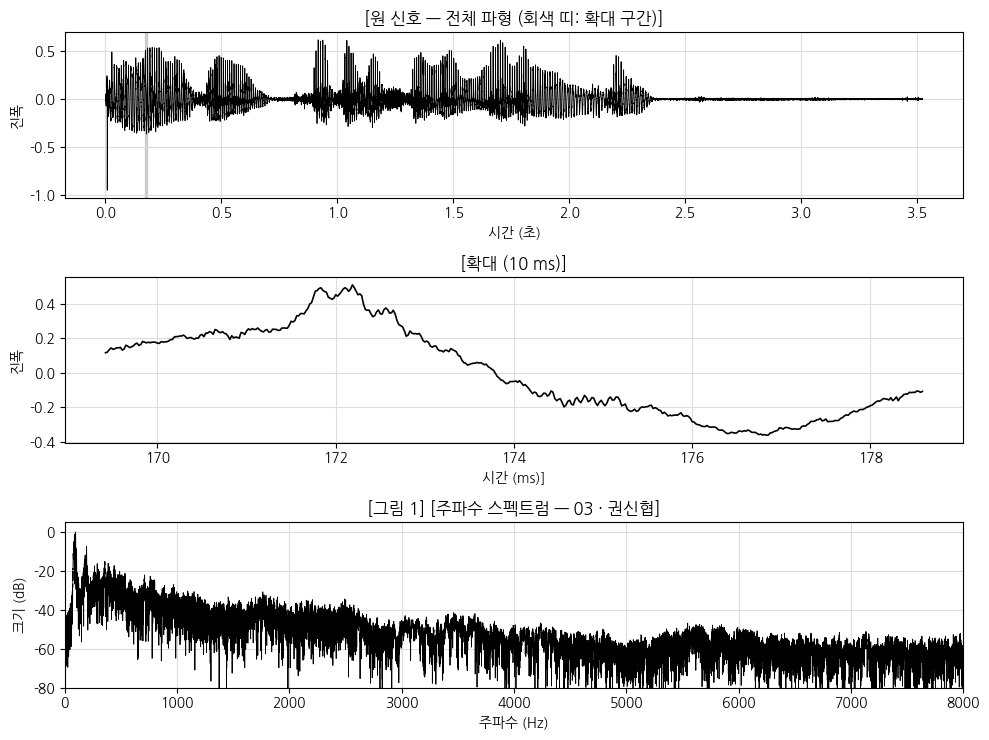

In [26]:
# ===== 2-4. [그림 1] 원 신호(메시지 신호) 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 녹음한 음성 전체 파형 (가로축: 시간 [s])
#   2) 일부 구간(수십 ms) 확대 파형
#   3) 주파수 스펙트럼 (가로축: 주파수 [Hz])
#   4) 그래프 제목에 '[그림 1]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5))

ax[0].plot(t, x, lw=0.6)
ax[0].axvspan(t[z0], t[z1], color="gray", alpha=0.3)
ax[0].set(title="[원 신호 — 전체 파형 (회색 띠: 확대 구간)]", xlabel="시간 (초)", ylabel="진폭")

ax[1].plot(t[z0:z1] * 1000, x[z0:z1], lw=1.2)
ax[1].set(title="[확대 (10 ms)]", xlabel="시간 (ms)]", ylabel="진폭")

f, X = spectrum(x, FS_ANALOG)
ax[2].plot(f, X, lw=0.6)
ax[2].set(title="[그림 1] [주파수 스펙트럼 — 03 · 권신협]", xlabel="주파수 (Hz)", ylabel="크기 (dB)",
          xlim=(0, 8000), ylim=(-80, 5))
plt.tight_layout()
plt.show()

---
## 3. AM 변조

$$s_{AM}(t) = A_c\,[\,1 + m\cdot x(t)\,]\cos(2\pi f_c t)$$

### 3-1. AM 변조 설계 📝

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|
| 반송파 주파수 | fc | 10000 | Hz | (작성) |
| 반송파 진폭 | Ac | 1.0 | V | (작성) |
| 변조지수 | m | 0.8 | - | (작성) |
| 메시지 최고 주파수 | fm | 1000 | Hz | (작성) |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | (작성) ※ fc + fm < Fs/2 확인 |

In [27]:
# ===== 3-2. AM 변조 파라미터 선언 (3-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fc, Ac, m, fm, Fs 를 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

FC = 10000   # 반송파 주파수 [Hz]
Ac = 1.0   # 반송파 진폭
M  = 0.8   # 변조지수
fm = 1000   # 메시지 최고 주파수 [Hz]
FS = 48000   # 변조용 샘플링 주파수 [Hz]

F_LOW  = 300     # 음성 대역 하한 [Hz]
F_HIGH = 3400    # 음성 대역 상한 [Hz] (전화 품질)
SNR_DB = 30      # 채널 잡음 (신호대잡음비, dB) — 작게 하면 잡음 증가

# 여기에 출력 코드를 작성하세요
print(f"FC: {FC}")
print(f"Ac: {Ac}")
print(f"M: {M}")
print(f"fm: {fm}")
print(f"FS: {FS}")

FC: 10000
Ac: 1.0
M: 0.8
fm: 1000
FS: 48000


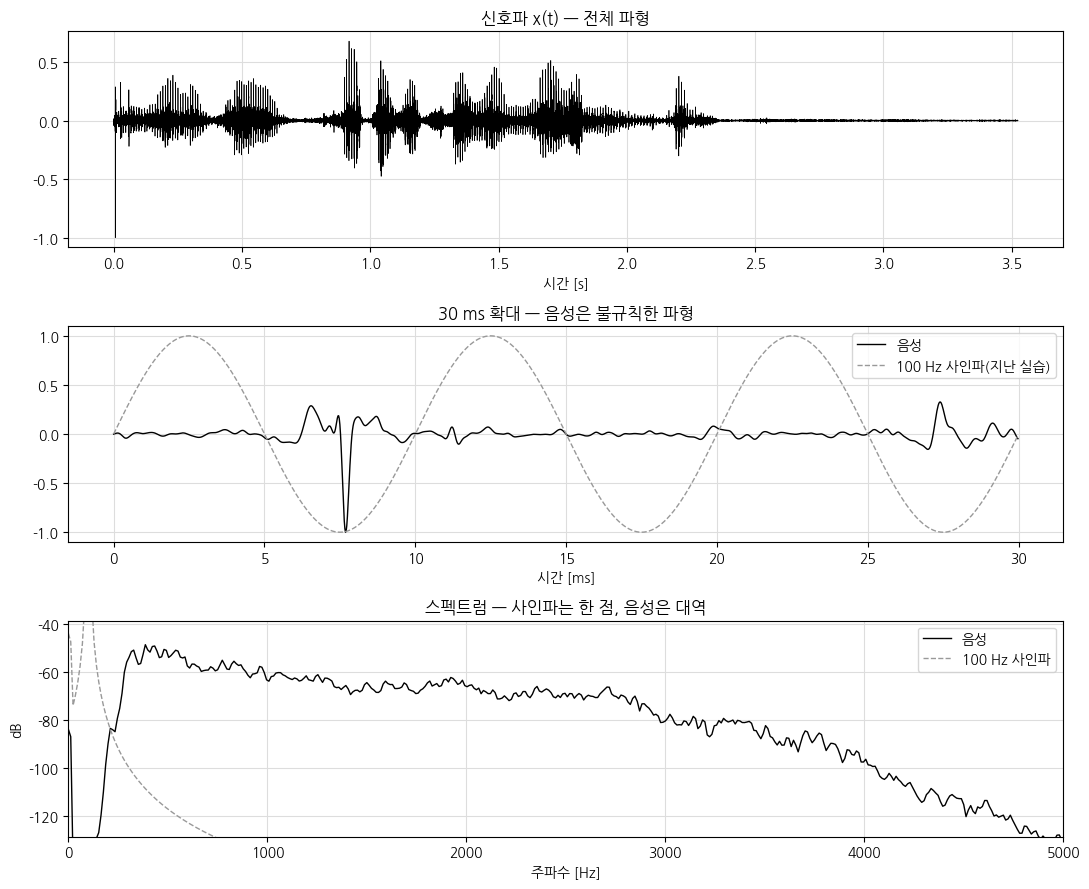

In [28]:
# ===== 3-3. AM 변조 구현 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 음성 신호를 정규화(|x(t)| ≤ 1)하고 필요하면 Fs 로 업샘플링
#   2) 반송파 c(t) 와 AM 신호 s(t) 생성
#   3) 포락선 최대·최소값, 측정 변조지수 (Amax−Amin)/(Amax+Amin) 출력
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
sos_bp = signal.butter(6, [F_LOW, F_HIGH], btype='band', fs=FS, output='sos')
msg = signal.sosfiltfilt(sos_bp, x)
msg = msg / (np.max(np.abs(msg)) + 1e-12)       # -1 ~ 1 정규화
t = np.arange(len(msg)) / FS

def spectrum_db(sig, fs=FS):
    f, P = signal.welch(sig, fs, nperseg=4096)
    return f, 10*np.log10(P + 1e-15)

# 비교용: 지난 실습의 100 Hz 사인파
sine = np.sin(2*np.pi*100*t)

fig, ax = plt.subplots(3, 1, figsize=(11, 9))
ax[0].plot(t, msg, 'k', lw=0.5); ax[0].set_title('신호파 x(t) — 전체 파형'); ax[0].set_xlabel('시간 [s]')
i0 = np.argmax(np.abs(msg)); w = int(0.03*FS); s0 = max(0, i0-w//2)
ax[1].plot(t[s0:s0+w]*1000, msg[s0:s0+w], 'k', lw=1, label='음성')
ax[1].plot(t[s0:s0+w]*1000, sine[s0:s0+w], color='0.6', ls='--', lw=1, label='100 Hz 사인파(지난 실습)')
ax[1].set_title('30 ms 확대 — 음성은 불규칙한 파형'); ax[1].set_xlabel('시간 [ms]'); ax[1].legend(loc='upper right')
f, Pm = spectrum_db(msg); _, Ps = spectrum_db(sine)
ax[2].plot(f, Pm, 'k', lw=1, label='음성'); ax[2].plot(f, Ps, color='0.6', ls='--', lw=1, label='100 Hz 사인파')
ax[2].set_xlim(0, 5000); ax[2].set_ylim(Pm.max()-80, Pm.max()+10)
ax[2].set_title('스펙트럼 — 사인파는 한 점, 음성은 대역'); ax[2].set_xlabel('주파수 [Hz]'); ax[2].set_ylabel('dB'); ax[2].legend()
plt.tight_layout(); plt.show()
display(Audio(msg, rate=FS))

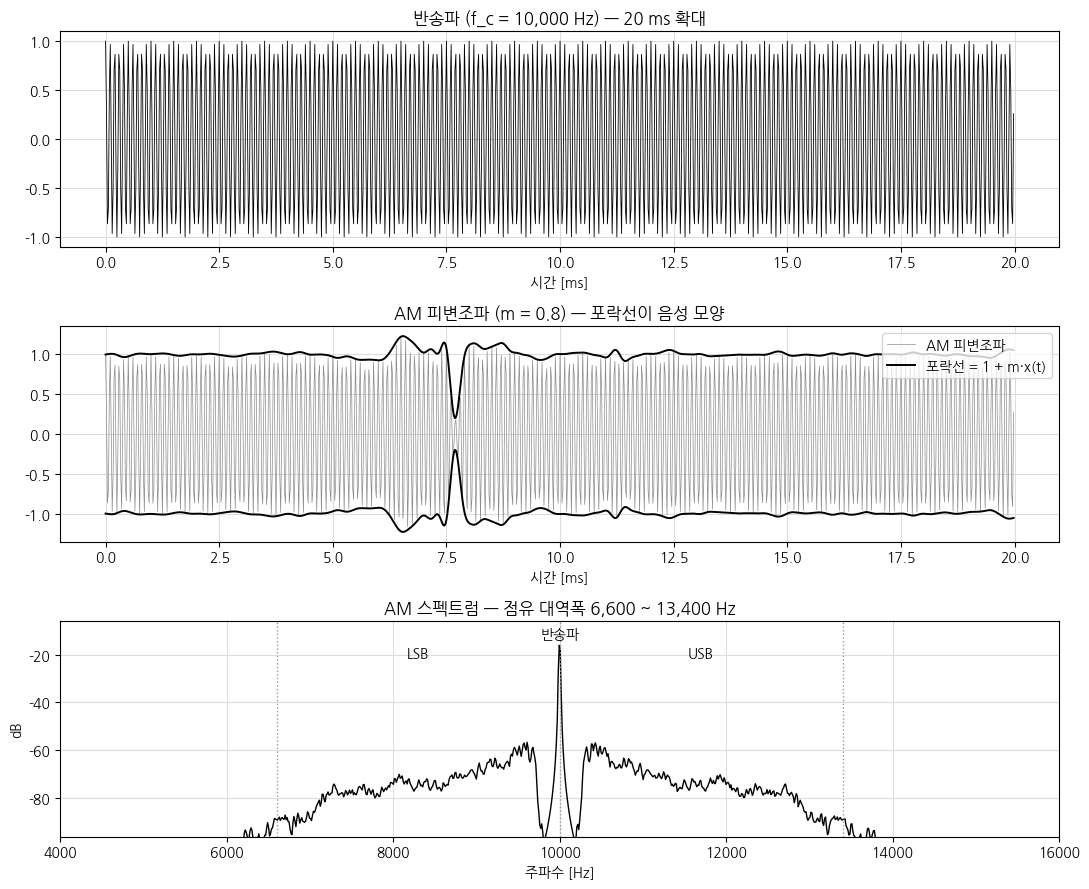

In [29]:
# ===== 3-4. [그림 2] AM 변조 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호 x(t)
#   2) 반송파 c(t) (확대)
#   3) AM 변조 파형 + 포락선
#   4) AM 스펙트럼 (fc, fc±fm 위치 표시)
#   5) 그래프 제목에 '[그림 2]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
carrier  = np.cos(2*np.pi*FC*t)
envelope = 1 + M*msg
am = envelope * carrier
am_tx = am / np.max(np.abs(am))                 # 송신용 정규화

fig, ax = plt.subplots(3, 1, figsize=(11, 9))
w = int(0.02*FS)
ax[0].plot(t[s0:s0+w]*1000, carrier[s0:s0+w], 'k', lw=0.6)
ax[0].set_title(f'반송파 (f_c = {FC:,} Hz) — 20 ms 확대'); ax[0].set_xlabel('시간 [ms]')
ax[1].plot(t[s0:s0+w]*1000, am[s0:s0+w], color='0.55', lw=0.5, label='AM 피변조파')
ax[1].plot(t[s0:s0+w]*1000,  envelope[s0:s0+w], 'k', lw=1.4, label='포락선 = 1 + m·x(t)')
ax[1].plot(t[s0:s0+w]*1000, -envelope[s0:s0+w], 'k', lw=1.4)
ax[1].set_title(f'AM 피변조파 (m = {M}) — 포락선이 음성 모양'); ax[1].set_xlabel('시간 [ms]'); ax[1].legend(loc='upper right')
f, Pa = spectrum_db(am)
ax[2].plot(f, Pa, 'k', lw=1)
for fx, lab in [(FC-F_HIGH, 'LSB'), (FC, '반송파'), (FC+F_HIGH, 'USB')]:
    ax[2].axvline(fx, color='0.6', ls=':', lw=1)
ax[2].text(FC-F_HIGH/2, Pa.max()-5, 'LSB', ha='center'); ax[2].text(FC+F_HIGH/2, Pa.max()-5, 'USB', ha='center')
ax[2].text(FC, Pa.max()+3, '반송파', ha='center')
ax[2].set_xlim(FC-6000, FC+6000); ax[2].set_ylim(Pa.max()-80, Pa.max()+10)
ax[2].set_title(f'AM 스펙트럼 — 점유 대역폭 {FC-F_HIGH:,} ~ {FC+F_HIGH:,} Hz'); ax[2].set_xlabel('주파수 [Hz]'); ax[2].set_ylabel('dB')
plt.tight_layout(); plt.show()

### 3-5. AM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 변조지수 m | (작성) | 측정: (작성) | (작성) |
| 대역폭 B | (작성) Hz | 스펙트럼 관찰: (작성) Hz | (작성) |
| 측파대 범위 | (작성) | (작성) | (작성) |
| 과변조 여부 | (작성) | (작성) | (작성) |

---
## 4. FM 변조

$$s_{FM}(t) = A_c\cos\!\Big(2\pi f_c t + 2\pi\,\Delta f\!\int_0^t x(\tau)\,d\tau\Big),\qquad f_i(t)=f_c+\Delta f\cdot x(t)$$

### 4-1. FM 변조 설계 📝 (⚠️ 코드를 작성하기 전에 먼저 작성)

| 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|
| 반송파 주파수 | fc | 10000 | Hz | AM과 같은 값으로 맞춰 두 방식을 같은 조건에서 비교하기 위해서입니다. 음성 최고 주파수(3400 Hz)보다 충분히 높아 반송파 한 주기 동안 음성이 거의 변하지 않습니다. |
| 반송파 진폭 | Ac | 1.0 | V | FM은 정보가 진폭이 아닌 주파수에 실리므로 진폭 값은 결과에 영향이 없습니다. AM과 같은 1.0 V로 두어 파형 크기를 비교하기 쉽게 했습니다. |
| 최대 주파수 편이 | Δf | 5000 | Hz | β = Δf / fm ≈ 1.5가 되어 순시 주파수가 변하는 모습이 그래프에서 뚜렷하게 보입니다. fc − Δf = 5000 Hz로 0 Hz보다 충분히 높아 주파수가 음수가 될 위험이 없습니다. |
| 메시지 최고 주파수 | fm | 3400 | Hz | 3-2에서 음성을 300~3400 Hz 대역으로 제한했으므로 메시지의 최고 주파수는 3400 Hz입니다. |
| 변조에 사용할 샘플링 주파수 | Fs | 48000 | Hz | AM과 같은 값이며 3장에서 만든 음성 신호를 그대로 사용할 수 있습니다. fc + Δf + fm = 10000 + 5000 + 3400 = 18400 Hz < Fs/2 = 24000 Hz이므로 조건을 만족합니다. |


In [ ]:
# ===== 4-2. FM 변조 파라미터 선언 (4-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fc, Ac, Δf, fm, Fs 를 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

fc_fm = 10000   # 반송파 주파수 [Hz]
Ac_fm = 1.0     # 반송파 진폭
df    = 5000    # 최대 주파수 편이 Δf [Hz]
fm    = 3400    # 메시지 최고 주파수 [Hz]
Fs    = 48000   # 변조용 샘플링 주파수 [Hz]

# 여기에 출력 코드를 작성하세요
print(f"fc_fm: {fc_fm} Hz")
print(f"Ac_fm: {Ac_fm} V")
print(f"df   : {df} Hz")
print(f"fm   : {fm} Hz")
print(f"Fs   : {Fs} Hz")
print(f"fc + Δf + fm = {fc_fm + df + fm} Hz  <  Fs/2 = {Fs // 2} Hz  →  {'조건 만족' if fc_fm + df + fm < Fs / 2 else '조건 불만족'}")

fc_fm: 10000 Hz
Ac_fm: 1.0 V
df   : 5000 Hz
fm   : 3400 Hz
Fs   : 48000 Hz
fc + Δf + fm = 18400 Hz  <  Fs/2 = 24000 Hz  →  조건 만족


In [ ]:
# ===== 4-3. FM 변조 구현 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호의 적분(누적합)으로 위상 생성
#   2) FM 신호 s(t) 생성
#   3) 순시 주파수 fi(t) 계산, 최대·최소 순시 주파수 출력
#   4) β, Carson 대역폭 출력
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
x_fm = msg                                    # 3장에서 만든 음성 신호 (300~3400 Hz, |x| ≤ 1)
t_fm = np.arange(len(x_fm)) / Fs              # 시간축 [s]

integral = np.cumsum(x_fm) / Fs               # ∫x(τ)dτ 를 누적합으로 근사
phase = 2 * np.pi * fc_fm * t_fm + 2 * np.pi * df * integral
s_fm = Ac_fm * np.cos(phase)                  # FM 신호

fi_fm = np.diff(phase) / (2 * np.pi) * Fs     # 순시 주파수 fi(t) = (1/2π)·dφ/dt
fi_fm = np.append(fi_fm, fi_fm[-1])           # 길이를 t_fm 과 맞춤

beta   = df / fm                              # 변조지수 β = Δf / fm
carson = 2 * (df + fm)                        # Carson 대역폭 B = 2(Δf + fm)

print(f"신호 길이: {len(s_fm):,}개 ({len(s_fm) / Fs:.2f}초)")
print(f"최대 순시 주파수: {fi_fm.max():,.1f} Hz (이론 fc + Δf = {fc_fm + df:,} Hz)")
print(f"최소 순시 주파수: {fi_fm.min():,.1f} Hz (이론 fc − Δf = {fc_fm - df:,} Hz)")
print(f"β = Δf / fm = {beta:.2f}")
print(f"Carson 대역폭 B = 2(Δf + fm) = {carson:,} Hz  ({fc_fm - carson // 2:,} ~ {fc_fm + carson // 2:,} Hz)")
print(f"FM 신호 진폭: 최대 {s_fm.max():.4f}, 최소 {s_fm.min():.4f}")

신호 길이: 169,156개 (3.52초)
최대 순시 주파수: 13,393.2 Hz (이론 fc + Δf = 15,000 Hz)
최소 순시 주파수: 5,000.0 Hz (이론 fc − Δf = 5,000 Hz)
β = Δf / fm = 1.47
Carson 대역폭 B = 2(Δf + fm) = 16,800 Hz  (1,600 ~ 18,400 Hz)
FM 신호 진폭: 최대 1.0000, 최소 -1.0000


스펙트럼 관찰(전력 99 %): 8,859 ~ 11,332 Hz → 대역폭 약 2,473 Hz
스펙트럼 관찰(최대값 −60 dB 이내): 6,574 ~ 14,238 Hz → 대역폭 약 7,664 Hz


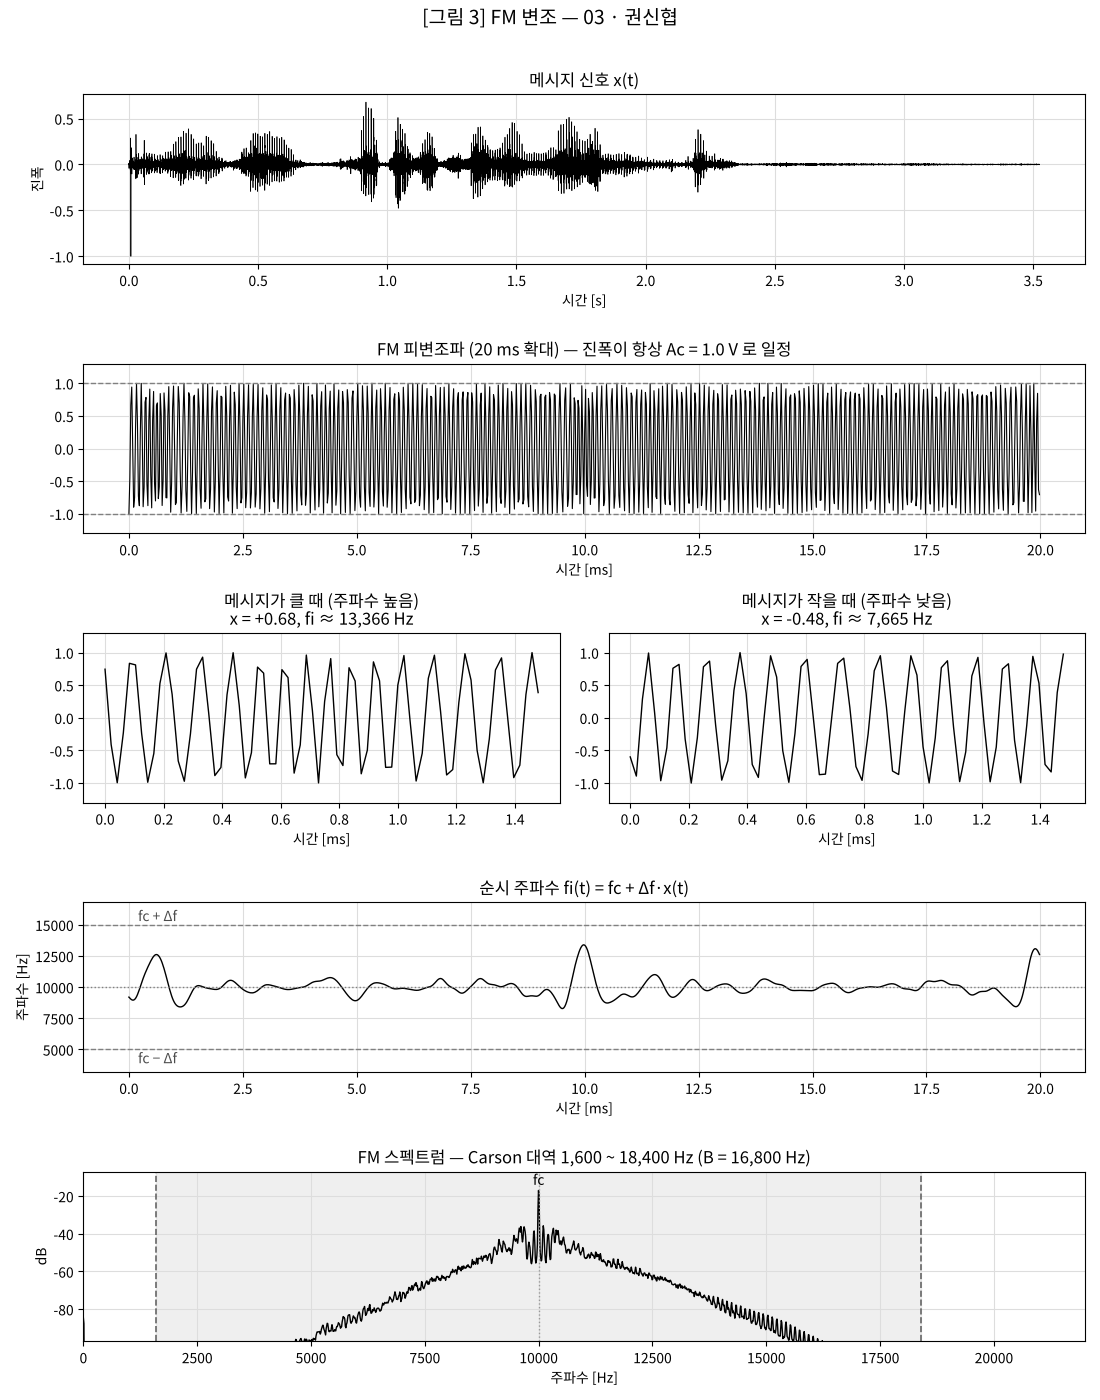

In [ ]:
# ===== 4-4. [그림 3] FM 변조 그래프 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 메시지 신호 x(t)
#   2) FM 변조 파형 (진폭 일정 확인)
#   3) 메시지가 클 때 / 작을 때의 FM 파형 확대 비교
#   4) 순시 주파수 fi(t)
#   5) FM 스펙트럼 (Carson 대역 표시)
#   6) 그래프 제목에 '[그림 3]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
# 확대 구간: 녹음 맨 앞의 필터 과도 응답(스파이크)을 피해 0.1초 이후 가장 큰 음성 부분 사용
n0 = int(0.1 * Fs)
zc = n0 + int(np.argmax(np.abs(x_fm[n0:])))
zs = max(0, zc - int(0.01 * Fs))             # 20 ms 구간의 시작 위치

fig = plt.figure(figsize=(11, 14))
gs = fig.add_gridspec(5, 2)
fig.suptitle("[그림 3] FM 변조 — 03 · 권신협", fontsize=14, y=0.995)

# 1) 메시지 신호
ax = fig.add_subplot(gs[0, :])
ax.plot(t_fm, x_fm, 'k', lw=0.5)
ax.set_title("메시지 신호 x(t)"); ax.set_xlabel("시간 [s]"); ax.set_ylabel("진폭")

# 2) FM 변조 파형 (20 ms 확대, 진폭 일정)
w = int(0.02 * Fs)
ax = fig.add_subplot(gs[1, :])
ax.plot((t_fm[zs:zs + w] - t_fm[zs]) * 1000, s_fm[zs:zs + w], 'k', lw=0.8)
ax.axhline(Ac_fm, color='0.5', ls='--', lw=1); ax.axhline(-Ac_fm, color='0.5', ls='--', lw=1)
ax.set_title(f"FM 피변조파 (20 ms 확대) — 진폭이 항상 Ac = {Ac_fm} V 로 일정")
ax.set_xlabel("시간 [ms]"); ax.set_ylim(-1.3, 1.3)

# 3) 메시지가 클 때 / 작을 때 비교 (1.5 ms 확대)
wz = int(0.0015 * Fs)
i_hi, i_lo = n0 + int(np.argmax(x_fm[n0:])), n0 + int(np.argmin(x_fm[n0:]))
for col, i_c, name in [(0, i_hi, "메시지가 클 때 (주파수 높음)"), (1, i_lo, "메시지가 작을 때 (주파수 낮음)")]:
    a = max(0, i_c - wz // 2)
    ax = fig.add_subplot(gs[2, col])
    ax.plot((t_fm[a:a + wz] - t_fm[a]) * 1000, s_fm[a:a + wz], 'k', lw=1)
    ax.set_title(f"{name}\nx = {x_fm[i_c]:+.2f}, fi ≈ {fi_fm[i_c]:,.0f} Hz")
    ax.set_xlabel("시간 [ms]"); ax.set_ylim(-1.3, 1.3)

# 4) 순시 주파수
ax = fig.add_subplot(gs[3, :])
ax.plot((t_fm[zs:zs + w] - t_fm[zs]) * 1000, fi_fm[zs:zs + w], 'k', lw=1)
ax.axhline(fc_fm, color='0.5', ls=':', lw=1)
ax.axhline(fc_fm + df, color='0.5', ls='--', lw=1); ax.axhline(fc_fm - df, color='0.5', ls='--', lw=1)
ax.text(0.2, fc_fm + df + 300, "fc + Δf", color='0.3')
ax.text(0.2, fc_fm - df - 1100, "fc − Δf", color='0.3')
ax.set_ylim(fc_fm - df - 1800, fc_fm + df + 1800)
ax.set_title("순시 주파수 fi(t) = fc + Δf·x(t)"); ax.set_xlabel("시간 [ms]"); ax.set_ylabel("주파수 [Hz]")

# 5) FM 스펙트럼
f, Pf = spectrum_db(s_fm, Fs)
ax = fig.add_subplot(gs[4, :])
ax.plot(f, Pf, 'k', lw=1)
for fx in (fc_fm - carson / 2, fc_fm + carson / 2):
    ax.axvline(fx, color='0.4', ls='--', lw=1.2)
ax.axvline(fc_fm, color='0.6', ls=':', lw=1)
ax.text(fc_fm, Pf.max() + 3, "fc", ha='center')
ax.axvspan(fc_fm - carson / 2, fc_fm + carson / 2, color='gray', alpha=0.12)
ax.set_xlim(0, 22000); ax.set_ylim(Pf.max() - 80, Pf.max() + 10)
ax.set_title(f"FM 스펙트럼 — Carson 대역 {fc_fm - carson // 2:,} ~ {fc_fm + carson // 2:,} Hz (B = {carson:,} Hz)")
ax.set_xlabel("주파수 [Hz]"); ax.set_ylabel("dB")

plt.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()

# 스펙트럼에서 읽은 대역폭 (전력의 99 %가 들어 있는 범위)
fw, Pw = signal.welch(s_fm, Fs, nperseg=4096)
cum = np.cumsum(Pw) / Pw.sum()
f_lo, f_hi = fw[np.searchsorted(cum, 0.005)], fw[np.searchsorted(cum, 0.995)]
print(f"스펙트럼 관찰(전력 99 %): {f_lo:,.0f} ~ {f_hi:,.0f} Hz → 대역폭 약 {f_hi - f_lo:,.0f} Hz")
Pw_db = 10 * np.log10(Pw + 1e-15)
above = fw[Pw_db > Pw_db.max() - 60]         # 최대값보다 60 dB 이내인 주파수
print(f"스펙트럼 관찰(최대값 −60 dB 이내): {above.min():,.0f} ~ {above.max():,.0f} Hz → 대역폭 약 {above.max() - above.min():,.0f} Hz")

### 4-5. FM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| β | Δf / fm = 5000 / 3400 ≈ 1.47 | 1.47 | 일치합니다. β가 1보다 커서 협대역보다는 광대역 FM에 가깝습니다. |
| Carson 대역폭 | 2(Δf + fm) = 16,800 Hz | 스펙트럼 관찰: 약 7,700 Hz (최대값 −60 dB 이내, 6,574 ~ 14,238 Hz) | 관찰값이 더 좁습니다. Carson 대역폭은 음성이 항상 최대 진폭(\|x\| = 1)인 최악의 경우를 기준으로 합니다. 실제 음성은 98 %의 구간에서 \|x\| < 0.2이고 실효값이 약 0.056이어서 평균 주파수 편이는 약 280 Hz에 그쳤습니다. 스펙트럼 전체는 Carson 대역(1,600 ~ 18,400 Hz) 안에 들어 있습니다. |
| 순시 주파수 범위 | 5,000 ~ 15,000 Hz | 5,000.0 ~ 13,393.2 Hz | 하한은 일치하고 상한은 낮습니다. 음성의 음의 피크가 −1.00, 양의 피크가 +0.68이어서 최대 순시 주파수는 10000 + 5000 × 0.68 ≈ 13,393 Hz가 되었습니다. |
| 신호 진폭 | 일정 (Ac) | 최대 1.0000, 최소 −1.0000 | 일치합니다. 메시지 크기가 변해도 진폭은 Ac = 1.0 V로 유지되고 주파수만 변했습니다. |


## 5. PCM (표본화 → 양자화 → 부호화)

```
 아날로그 m(t) ──▶ [① 표본화 fs] ──▶ [② 양자화 n비트] ──▶ [③ 부호화] ──▶ 0110 1001 0111 …
```

### 5-1. PCM 설계 📝

| 단계 | 항목 | 기호 | 내가 선택한 값 | 단위 | 이 값을 선택한 이유 |
|---|---|---|---|---|---|
| 표본화 | 표본화 주파수 | fs | 8000 | Hz | 음성 최고 주파수가 3400 Hz이므로 2fm = 6800 Hz 이상이어야 합니다. 8000 Hz는 전화망 표준이며 나이퀴스트 조건을 만족하고 여유도 있습니다. ※ 나이퀴스트 조건 fs ≥ 2fm |
| 양자화 | 양자화 비트 수 | n | 8 | bit | 전화망 PCM(G.711)이 쓰는 표준 비트 수입니다. 256개 레벨로 음성을 알아들을 수 있는 품질을 얻을 수 있습니다. |
| 양자화 | 양자화 방식 | - | ☑ 균일(선형) ☐ 비균일(μ-law 등) | - | 구조가 단순하고 이론 SQNR(6.02n + 1.76)과 측정값을 바로 비교할 수 있습니다. |
| 양자화 | 진폭 범위 | - | -1.0 ~ +1.0 | V | 3장에서 음성을 \|x\| ≤ 1로 정규화했으므로 같은 범위를 그대로 사용했습니다. |
| 부호화 | 부호화 방식 | - | ☑ 자연 2진 ☐ 부호-크기 ☐ 2의 보수 ☐ 기타 | - | 레벨 번호(0~255)를 그대로 2진수로 바꾸는 방식이라 표본값과 부호의 대응을 확인하기 쉽습니다. |
| 출력 | 일련 데이터 표시 범위 | - | 1 번째 표본부터 16 개 | - | 16개 × 8비트 = 128비트로 한 화면에서 비교하기 알맞은 길이입니다. |

**설계 단계 예상값 (계산)**

| 항목 | 계산식 | 예상값 | 단위 |
|---|---|---|---|
| 표본화 주기 | Ts = 1 / fs | 125 | μs |
| 나이퀴스트 율 | 2fm | 6800 | Hz |
| 양자화 레벨 수 | L = 2ⁿ | 256 | 개 |
| 양자화 간격 | Δ = (진폭 범위) / L | 2 / 256 = 0.0078125 | V |
| 이론 SQNR | 6.02n + 1.76 | 49.92 | dB |
| 비트율 | R = fs × n | 64,000 | bps |


In [ ]:
# ===== 5-2. PCM 파라미터 선언 (5-1 설계표의 값과 같아야 함) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 fs, n 등을 변수로 선언하고 print 로 출력
# ------------------------------------------------------------

fs_pcm = 8000   # 표본화 주파수 [Hz]
n_bits = 8      # 양자화 비트 수

# 여기에 출력 코드를 작성하세요
V_MIN, V_MAX = -1.0, 1.0      # 양자화 진폭 범위 [V]
SHOW_START, SHOW_N = 1, 16    # 일련 데이터 표시 범위 (1번째 표본부터 16개)

L_pcm = 2 ** n_bits           # 양자화 레벨 수
delta = (V_MAX - V_MIN) / L_pcm   # 양자화 간격

print(f"fs_pcm : {fs_pcm} Hz  (표본화 주기 Ts = {1e6 / fs_pcm:.0f} μs)")
print(f"n_bits : {n_bits} bit")
print(f"양자화 방식: 균일(선형), 진폭 범위 {V_MIN} ~ {V_MAX} V")
print(f"부호화 방식: 자연 2진")
print(f"나이퀴스트 조건: fs = {fs_pcm} Hz ≥ 2·fm = {2 * fm} Hz  →  {'만족' if fs_pcm >= 2 * fm else '불만족'}")
print(f"레벨 수 L = {L_pcm}, 양자화 간격 Δ = {delta:.7f}")
print(f"이론 SQNR = {6.02 * n_bits + 1.76:.2f} dB, 비트율 R = {fs_pcm * n_bits:,} bps")
print(f"표시 범위: {SHOW_START}번째 표본부터 {SHOW_N}개")

fs_pcm : 8000 Hz  (표본화 주기 Ts = 125 μs)
n_bits : 8 bit
양자화 방식: 균일(선형), 진폭 범위 -1.0 ~ 1.0 V
부호화 방식: 자연 2진
나이퀴스트 조건: fs = 8000 Hz ≥ 2·fm = 6800 Hz  →  만족
레벨 수 L = 256, 양자화 간격 Δ = 0.0078125
이론 SQNR = 49.92 dB, 비트율 R = 64,000 bps
표시 범위: 1번째 표본부터 16개


표본화 주파수 8000 Hz → 표본 수 28,193개 (길이 3.52초)
표본값 앞 8개: [-0.0007  0.0099 -0.0073 -0.04   -0.0308 -0.0008  0.0134  0.0084]


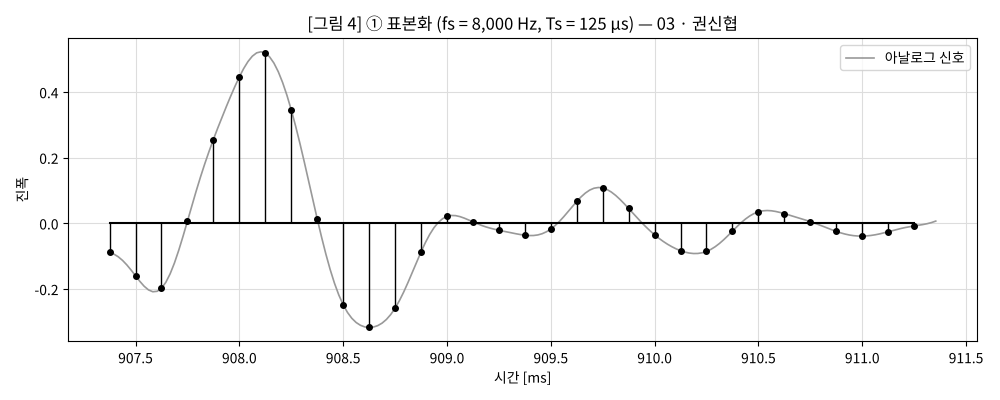

In [ ]:
# ===== 5-3. [그림 4] ① 표본화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 음성 신호를 fs 로 표본화한 표본값 배열
#   2) 아날로그 신호 위에 표본점(stem)을 겹친 그래프 (수 ms 구간)
#   3) 표본 수 출력
#   4) 그래프 제목에 '[그림 4]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
assert FS % fs_pcm == 0, "FS 가 fs_pcm 의 정수배여야 합니다"
step = FS // fs_pcm                         # 아날로그 표본 6개마다 1개를 뽑음
x_pcm = msg[::step]                         # 표본값 배열 x[k]
t_pcm = np.arange(len(x_pcm)) / fs_pcm      # 표본 시각 [s]

print(f"표본화 주파수 {fs_pcm} Hz → 표본 수 {len(x_pcm):,}개 (길이 {len(x_pcm) / fs_pcm:.2f}초)")
print("표본값 앞 8개:", np.round(x_pcm[:8], 4))

k0 = zs // step                             # 그림 3 에서 고른 음성 구간에서 4 ms
k1 = k0 + int(0.004 * fs_pcm)
a0, a1 = k0 * step, k1 * step

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_fm[a0:a1] * 1000, msg[a0:a1], color='0.6', lw=1.2, label='아날로그 신호')
ml, sl, bl = ax.stem(t_pcm[k0:k1] * 1000, x_pcm[k0:k1], linefmt='k-', markerfmt='ko', basefmt='k-')
plt.setp(sl, linewidth=1); plt.setp(ml, markersize=4)
ax.set_title(f"[그림 4] ① 표본화 (fs = {fs_pcm:,} Hz, Ts = {1e6 / fs_pcm:.0f} μs) — 03 · 권신협")
ax.set_xlabel("시간 [ms]"); ax.set_ylabel("진폭"); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

양자화 레벨 수 L = 256, 간격 Δ = 0.0078125
  표본       표본값    레벨 번호      양자화 값
   1   -0.0007      127    -0.0039
   2    0.0099      129     0.0117
   3   -0.0073      127    -0.0039
   4   -0.0400      122    -0.0430
   5   -0.0308      124    -0.0273
   6   -0.0008      127    -0.0039
   7    0.0134      129     0.0117
   8    0.0084      129     0.0117
최대 양자화 오차 = 0.00391  (이론 최대 Δ/2 = 0.00391)
측정 SQNR = 27.68 dB  (이론 6.02n + 1.76 = 49.92 dB)


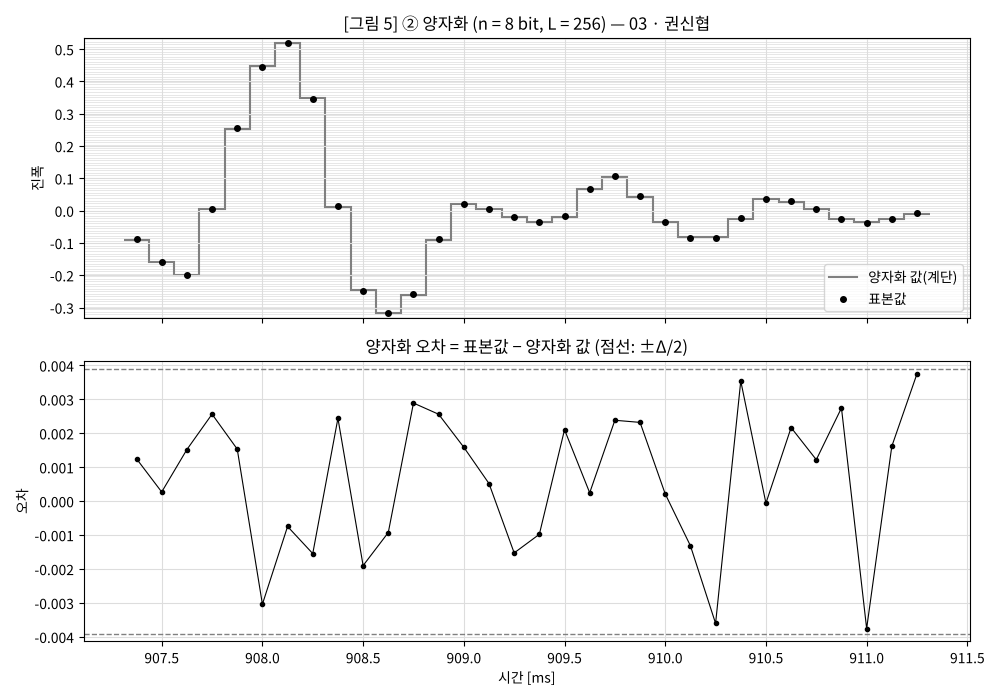

In [ ]:
# ===== 5-4. [그림 5] ② 양자화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 표본값을 L 개 레벨로 양자화한 레벨 번호와 양자화 값
#   2) 표본값과 양자화 값(계단)을 겹친 그래프 + 양자화 레벨선
#   3) 양자화 오차 그래프
#   4) 측정 SQNR 출력
#   5) 그래프 제목에 '[그림 5]'와 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
q_idx = np.clip(np.floor((x_pcm - V_MIN) / delta), 0, L_pcm - 1).astype(int)   # 레벨 번호 0 ~ L-1
x_q = V_MIN + (q_idx + 0.5) * delta                                             # 각 레벨의 중앙값
err = x_pcm - x_q                                                               # 양자화 오차

sqnr = 10 * np.log10(np.mean(x_pcm ** 2) / np.mean(err ** 2))

print(f"양자화 레벨 수 L = {L_pcm}, 간격 Δ = {delta:.7f}")
print(f"{'표본':>4} {'표본값':>9} {'레벨 번호':>8} {'양자화 값':>10}")
for k in range(8):
    print(f"{k + 1:>4} {x_pcm[k]:>9.4f} {q_idx[k]:>8d} {x_q[k]:>10.4f}")
print(f"최대 양자화 오차 = {np.abs(err).max():.5f}  (이론 최대 Δ/2 = {delta / 2:.5f})")
print(f"측정 SQNR = {sqnr:.2f} dB  (이론 6.02n + 1.76 = {6.02 * n_bits + 1.76:.2f} dB)")

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
lv = V_MIN + (np.arange(L_pcm + 1)) * delta                      # 레벨 경계선
lo, hi = x_pcm[k0:k1].min() - 2 * delta, x_pcm[k0:k1].max() + 2 * delta
for v in lv[(lv > lo) & (lv < hi)]:
    ax[0].axhline(v, color='#dddddd', lw=0.5, zorder=0)
ax[0].stairs(x_q[k0:k1], np.append(t_pcm[k0:k1], t_pcm[k1 - 1] + 1 / fs_pcm) * 1000 - 0.5 / fs_pcm * 1000,
             color='gray', lw=1.5, baseline=None, label='양자화 값(계단)')
ax[0].plot(t_pcm[k0:k1] * 1000, x_pcm[k0:k1], 'ko', ms=4, label='표본값')
ax[0].set_ylim(lo, hi)
ax[0].set_title(f"[그림 5] ② 양자화 (n = {n_bits} bit, L = {L_pcm}) — 03 · 권신협")
ax[0].set_ylabel("진폭"); ax[0].legend(loc='lower right')

ax[1].plot(t_pcm[k0:k1] * 1000, err[k0:k1], 'k.-', lw=0.8)
ax[1].axhline(delta / 2, color='0.5', ls='--', lw=1); ax[1].axhline(-delta / 2, color='0.5', ls='--', lw=1)
ax[1].set_title("양자화 오차 = 표본값 − 양자화 값 (점선: ±Δ/2)")
ax[1].set_xlabel("시간 [ms]"); ax[1].set_ylabel("오차")
plt.tight_layout(); plt.show()

  표본       표본값    레벨  2진 부호
   1   -0.0007   127  01111111
   2    0.0099   129  10000001
   3   -0.0073   127  01111111
   4   -0.0400   122  01111010
   5   -0.0308   124  01111100
   6   -0.0008   127  01111111
   7    0.0134   129  10000001
   8    0.0084   129  10000001


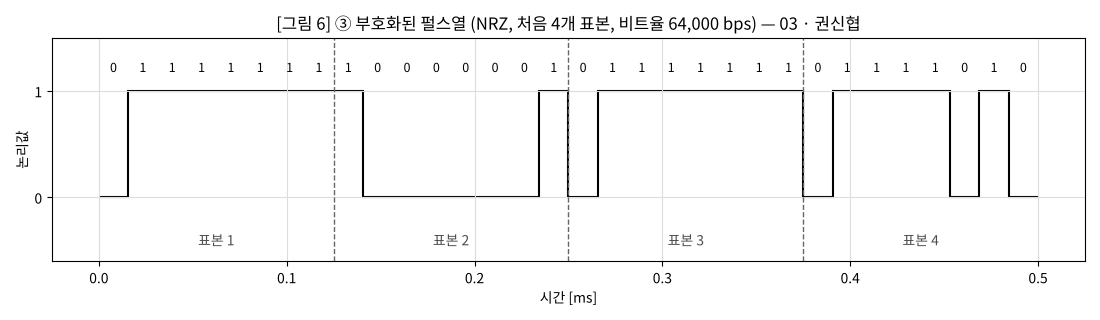

In [ ]:
# ===== 5-5. [그림 6] ③ 부호화 =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 양자화 레벨 번호를 n 비트 2진 부호로 변환
#   2) 부호화 표 (표본 번호 · 표본값 · 레벨 · 2진 부호) 일부 출력
#   3) 부호화된 펄스열(NRZ) 그래프
#   4) 그래프 제목에 '[그림 6]'과 본인 번호·이름
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
codes = [format(int(q), f"0{n_bits}b") for q in q_idx]      # 레벨 번호 → 자연 2진 부호

print(f"{'표본':>4} {'표본값':>9} {'레벨':>5}  2진 부호")
for k in range(8):
    print(f"{k + 1:>4} {x_pcm[k]:>9.4f} {q_idx[k]:>5d}  {codes[k]}")

N_PLOT = 4                                                   # 처음 4개 표본 = 32 비트
bits = np.array([int(b) for b in "".join(codes[:N_PLOT])])
tb = np.arange(len(bits) + 1) / (fs_pcm * n_bits) * 1000     # 비트 경계 시각 [ms]

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.stairs(bits, tb, color='k', lw=1.5)
for i, b in enumerate(bits):
    ax.text((tb[i] + tb[i + 1]) / 2, 1.18, str(b), ha='center', fontsize=9)
for k in range(1, N_PLOT):
    ax.axvline(tb[k * n_bits], color='0.4', ls='--', lw=1)
for k in range(N_PLOT):
    ax.text((tb[k * n_bits] + tb[(k + 1) * n_bits]) / 2, -0.45, f"표본 {k + 1}", ha='center', color='0.3')
ax.set_ylim(-0.6, 1.5); ax.set_yticks([0, 1])
ax.set_title(f"[그림 6] ③ 부호화된 펄스열 (NRZ, 처음 {N_PLOT}개 표본, 비트율 {fs_pcm * n_bits:,} bps) — 03 · 권신협")
ax.set_xlabel("시간 [ms]"); ax.set_ylabel("논리값")
plt.tight_layout(); plt.show()

In [ ]:
# ===== 5-6. 부호화 일련 데이터 출력 (앞부분부터) =====
# [이 셀의 실행 결과에 반드시 나와야 할 것]
#   1) 설계표의 표시 범위대로, 부호화 데이터의 앞부분부터 연속된 비트열 출력
#   2) 표본 단위로 띄어 쓴 형태와 연속 비트열 형태 모두
#   3) 출력한 표본 수와 비트 수
# ------------------------------------------------------------

# 여기에 코드를 작성하세요
show = codes[SHOW_START - 1:SHOW_START - 1 + SHOW_N]
print("표본 단위로 띄어 쓴 형태:")
print(" ".join(show))
print()
print("연속 비트열 형태:")
print("".join(show))
print()
print(f"출력한 표본 수: {len(show)}개, 비트 수: {len(''.join(show))}비트 ({len(show)} × {n_bits})")
print(f"전체: 표본 {len(codes):,}개, 비트 {len(codes) * n_bits:,}비트")

표본 단위로 띄어 쓴 형태:
01111111 10000001 01111111 01111010 01111100 01111111 10000001 10000001 10000000 10000001 10000010 10000001 01111110 01111101 01111110 10000000

연속 비트열 형태:
01111111100000010111111101111010011111000111111110000001100000011000000010000001100000101000000101111110011111010111111010000000

출력한 표본 수: 16개, 비트 수: 128비트 (16 × 8)
전체: 표본 28,193개, 비트 225,544비트


### 5-7. PCM 결과 기록 📝

| 항목 | 설계값(예상) | 실행 결과 | 일치 여부 / 차이 이유 |
|---|---|---|---|
| 표본화 주파수 / 표본 수 | 8000 Hz / 약 28,193개 (169,156 ÷ 6) | 8000 Hz / 28,193개 | 일치합니다. 아날로그 표본 6개마다 1개를 뽑았고 길이는 3.52초입니다. |
| 양자화 레벨 수 L | 256 | 256 | 일치합니다. 레벨 번호는 0~255이고 최대 양자화 오차는 Δ/2 = 0.0039였습니다. |
| SQNR | 이론 49.92 dB | 측정 27.68 dB | 측정값이 약 22 dB 낮습니다. 이론식은 −1 ~ +1 V를 가득 채우는 사인파를 가정합니다. 이번 음성은 98 %의 구간에서 \|x\| < 0.2이고 신호 전력이 약 0.003(실효값 0.056)으로 작습니다. 오차 전력(Δ²/12)은 같으므로 SQNR이 낮아졌습니다. |
| 비트율 / 전체 비트 수 | 64,000 bps / 28,193 × 8 = 225,544비트 | 64,000 bps / 225,544비트 | 일치합니다. 음성 3.52초가 약 22.5만 비트로 변환되었습니다. |

**부호화 일련 데이터 (5-6 출력 붙여넣기)**
```
표본 단위로 띄어 쓴 형태:
01111111 10000001 01111111 01111010 01111100 01111111 10000001 10000001 10000000 10000001 10000010 10000001 01111110 01111101 01111110 10000000

연속 비트열 형태:
01111111100000010111111101111010011111000111111110000001100000011000000010000001100000101000000101111110011111010111111010000000

출력한 표본 수: 16개, 비트 수: 128비트 (16 × 8)
```


---
## ✅ 제출 전 체크리스트
- [ ] 번호, 이름을 작성했다
- [ ] 내 목소리를 입력했고 재생된다.
- [ ] **설계표를 코드 작성 전에** 작성했고, 선언한 변수값과 일치한다
- [ ] [그림 1] ~ [그림 5] 그래프가 모두 출력되어 있고 제목에 번호 · 이름이 있다
- [ ] 부호화 일련 데이터(앞부분)가 출력되어 있다
- [ ] 결과 기록표와 고찰을 모두 작성했다
- [ ] **런타임 → 모두 실행** 후 오류 없이 저장했다